# Mitotic cell division simulation


In [1]:
import importlib
import sys
sys.path.insert(0, '/home/mcorbeau/Bureau/vertax/src/vertax/mitotic_spindle')
import os
os.environ.setdefault('JAX_PLATFORMS', 'cpu')
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')
os.environ.setdefault('JAX_ENABLE_X64', 'true')

import math
import optax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from vertax import BoundedMesh, BoundedBilevelOptimizer, plot_mesh
from vertax import EdgePlot, FacePlot, VertexPlot
from vertax.topo import update_T1_bounded

from mesh_utils import get_cell_segments
from spindle_model import find_spindle
from visualization import _plot_spindle_fig, _plot_post_div_fig, _plot_opt_fig

import energy_adaptive; importlib.reload(energy_adaptive)
from energy_adaptive import energy_adaptive
import cell_division; importlib.reload(cell_division)
from cell_division import divide_cell
import visualization; importlib.reload(visualization)
from visualization import _plot_spindle_fig, _plot_post_div_fig, _plot_opt_fig

In [2]:
import math

n_cells = 20
width = math.sqrt(n_cells)
height = width

mesh = BoundedMesh.from_random_seeds(nb_seeds=n_cells, width=width, height=height, random_key=2)


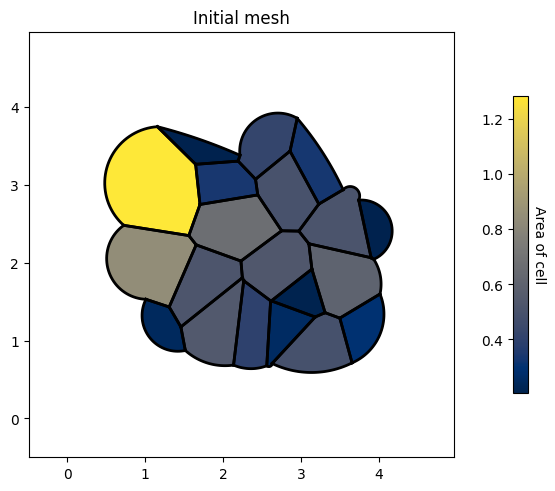

In [3]:
_mesh_plot = BoundedMesh.copy_mesh(mesh); _mesh_plot.angles = jnp.clip(_mesh_plot.angles, 0.017, jnp.pi/2 - 0.01)
_total_area = float(jnp.sum(mesh.get_area(jnp.arange(mesh.nb_faces))))
plot_mesh(_mesh_plot,
          face_plot=FacePlot.AREA,
          title=f"Initial mesh — total area: {_total_area:.3f}")
plt.show()

In [4]:
mesh.vertices_params = jnp.asarray([0.0 for _ in range(mesh.nb_vertices)])

key = jax.random.PRNGKey(3)
mesh.edges_params = 1 + jax.nn.sigmoid(jax.random.uniform(key, (mesh.nb_edges,)) * 20 - 10)

mesh.faces_params = jnp.asarray([0.6 for _ in range(mesh.nb_faces)])


In [ ]:
bilevel_optimizer = BoundedBilevelOptimizer()
bilevel_optimizer.loss_function_inner = energy_adaptive
bilevel_optimizer.inner_solver        = optax.adam(learning_rate=1e-4)
bilevel_optimizer.update_T1           = True
bilevel_optimizer._update_T1_func     = update_T1_bounded
bilevel_optimizer.min_dist_T1         = 0.01
bilevel_optimizer.max_nb_iterations   = 2000
bilevel_optimizer.tolerance           = 1e-6
bilevel_optimizer.patience            = 50

loss_history = bilevel_optimizer.inner_optimization(mesh)


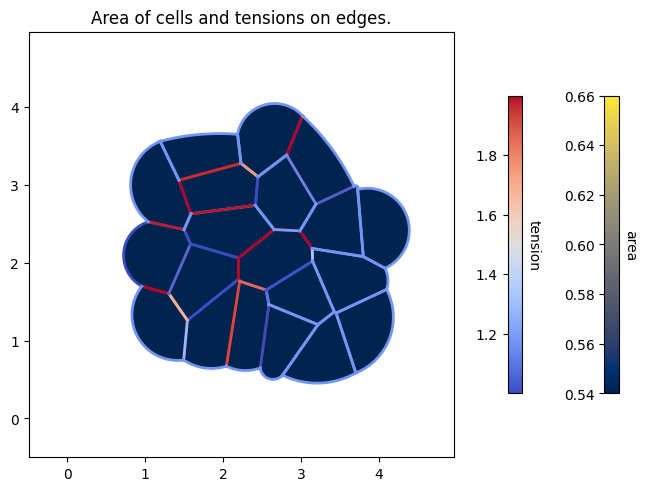

In [6]:
_mesh_plot = BoundedMesh.copy_mesh(mesh); _mesh_plot.angles = jnp.clip(_mesh_plot.angles, 0.017, jnp.pi/2 - 0.01)
_total_area = float(jnp.sum(mesh.get_area(jnp.arange(mesh.nb_faces))))
plot_mesh(_mesh_plot, edge_plot=EdgePlot.EDGE_PARAMETER, edge_parameters_name="tension",
          face_plot=FacePlot.AREA,
          vertex_plot=VertexPlot.INVISIBLE,
          title=f"After relaxation — total area: {_total_area:.3f}")
plt.show()


## Mitotic spindle


In [7]:
import importlib
import spindle_model; importlib.reload(spindle_model)
import cell_division; importlib.reload(cell_division)
from spindle_model import find_spindle
from cell_division import divide_cell

# Find a divisible cell (spindle converges + exactly 2 cuts)
import numpy as np
rng = np.random.default_rng(42)
face_id = None
c = u = c1 = c2 = v0s = v1s = None
for fid in rng.permutation(mesh.nb_faces).tolist():
    try:
        from mesh_utils import get_cell_segments
        v0s_try, v1s_try, tensions_try = get_cell_segments(fid, mesh)
        c_try, u_try, c1_try, c2_try = find_spindle(fid, mesh, d_fraction=0.3, n_gauss=12)
        mesh_test = BoundedMesh.copy_mesh(mesh)
        divide_cell(mesh_test, fid, c_try, u_try)
        face_id, c, u, c1, c2 = fid, c_try, u_try, c1_try, c2_try
        v0s, v1s = v0s_try, v1s_try
        break
    except Exception as e:
        print(f"  face {fid} skipped: {e}")
        continue

if face_id is None:
    raise RuntimeError("No divisible cell found.")

print(f"Selected cell: {face_id}")
print(f"Center: ({c[0]:.4f}, {c[1]:.4f})")
print(f"Spindle axis u: ({u[0]:.4f}, {u[1]:.4f})")


Cellule 5 — spindle
  Centre    : (3.1794, 3.4356)
  Axe u     : (0.8838, 0.4679)
  Résidu    : 2.58e-12
Centre : (3.1794, 3.4356)
Axe u  : (0.8838, 0.4679)


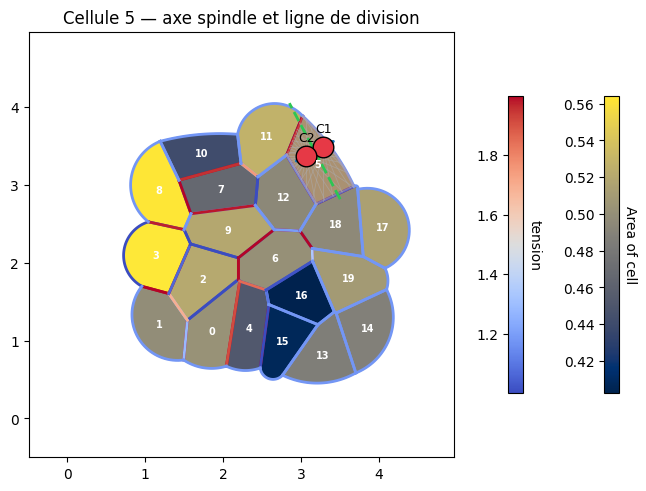

In [8]:
_plot_spindle_fig(mesh, face_id, c, u, c1, c2, v0s, v1s)
plt.show()

## Cell division


In [9]:
mesh_post, _ = divide_cell(mesh, face_id, c, u)

print(f"Before: {mesh.nb_faces} cells")
print(f"After: {mesh_post.nb_faces} cells")


Division cellule 5 → faces 5 et 20 (2 nouveau(x) sommet(s))
Avant : 20 cellules
Apres : 21 cellules


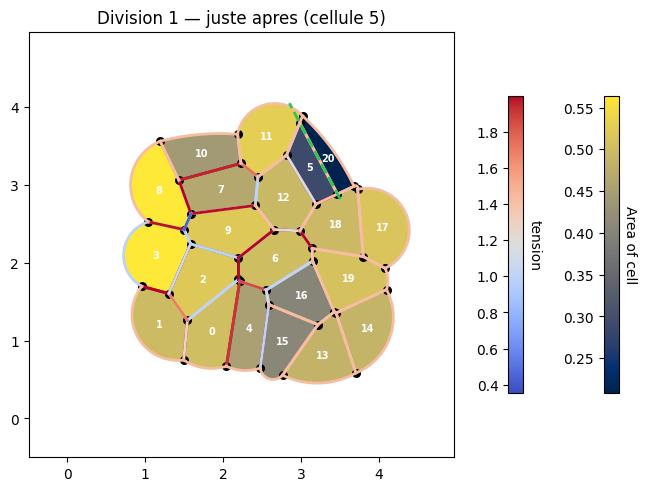

In [10]:
_plot_post_div_fig(mesh, mesh_post, face_id, c, u, division_idx=1)
plt.show()

## Post-division relaxation


In [ ]:
mesh_opt = BoundedMesh.copy_mesh(mesh_post)
# Target = initial_total_area / current_nb_faces
total_area = float(jnp.sum(mesh.get_area(jnp.arange(mesh.nb_faces))))
target_area = total_area / mesh_opt.nb_faces
mesh_opt.faces_params = jnp.full(mesh_opt.nb_faces, target_area)
print(f"Target area: {target_area:.4f} (initial total {total_area:.4f} / {mesh_opt.nb_faces} cells)")

opt = BoundedBilevelOptimizer()
opt.loss_function_inner = energy_adaptive
opt.inner_solver        = optax.adam(learning_rate=1e-4)
opt.update_T1           = True
opt._update_T1_func     = update_T1_bounded
opt.min_dist_T1         = 0.01
opt.max_nb_iterations   = 2000
opt.tolerance           = 1e-6
opt.patience            = 50

print(f"Before: {mesh_opt.nb_faces} cells, {mesh_opt.nb_edges} edges")
loss_hist = opt.inner_optimization(mesh_opt)
print(f"After: {mesh_opt.nb_faces} cells, {mesh_opt.nb_edges} edges")
print(f"{len(loss_hist)} iterations, loss = {float(loss_hist[-1]):.4f}")

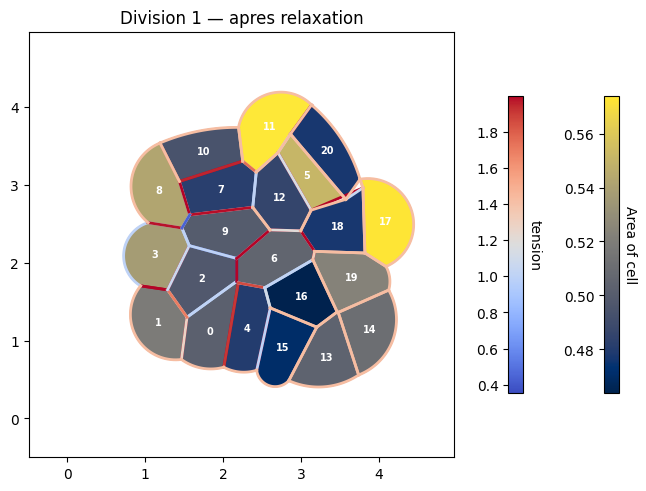

In [12]:
_plot_opt_fig(mesh_opt, division_idx=1)
plt.show()

## 5 consecutive divisions


In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions, _pick_face

mesh_div = BoundedMesh.from_random_seeds(nb_seeds=n_cells, width=width, height=height, random_key=2)
mesh_div.vertices_params = jnp.asarray([0.0 for _ in range(mesh_div.nb_vertices)])
mesh_div.edges_params    = 1 + jax.nn.sigmoid(jax.random.uniform(key, (mesh_div.nb_edges,)) * 20 - 10)
mesh_div.faces_params    = jnp.asarray([0.6 for _ in range(mesh_div.nb_faces)])

mesh_final, division_snapshots = run_n_divisions(mesh_div, n_divisions=5)
print(f"Final tissue: {mesh_final.nb_faces} cells, {mesh_final.nb_edges} edges")


In [ ]:
from visualization import _clip_angles, _add_cell_labels, PLOT_KWARGS
from vertax import get_plot_mesh
import numpy as np

def _snap_to_image(snap, title):
    """Render a mesh into a numpy RGBA image via an offscreen figure."""
    m = _clip_angles(snap)
    ta = float(jnp.sum(snap.get_area(jnp.arange(snap.nb_faces))))
    fig_tmp, ax_tmp = get_plot_mesh(m, title=f"{title} — area: {ta:.3f}", **PLOT_KWARGS)
    _add_cell_labels(ax_tmp, snap)
    fig_tmp.canvas.draw()
    w, h = fig_tmp.canvas.get_width_height()
    img = np.frombuffer(fig_tmp.canvas.tostring_argb(), dtype=np.uint8).reshape(h, w, 4)
    img = np.roll(img, -1, axis=2)  # ARGB -> RGBA
    plt.close(fig_tmp)
    return img

fig, axes = plt.subplots(5, 2, figsize=(16, 25))
fig.suptitle("5 divisions  |  left: just after division  ·  right: after relaxation",
             fontsize=13, y=1.002)

for div_idx, (snap_post, snap_opt) in enumerate(division_snapshots, start=1):
    for col, (snap, label) in enumerate([
            (snap_post, f"Division {div_idx} — just after ({snap_post.nb_faces} cells)"),
            (snap_opt,  f"Division {div_idx} — after relaxation ({snap_opt.nb_faces} cells)"),
    ]):
        img = _snap_to_image(snap, label)
        axes[div_idx - 1, col].imshow(img)
        axes[div_idx - 1, col].axis("off")

plt.tight_layout()
plt.show()


## 5 consecutive divisions — PDF method (mode)

### Orientation probability density

Following Théry et al., the division axis orientation $\alpha$ is governed by a Boltzmann-like probability density:

$$\boxed{p(\alpha) = p_0 \exp\!\left(-\frac{\bar{V}(\alpha)}{C}\right)}$$

where each term is:

| Symbol | Meaning |
|--------|---------|
| $\alpha \in [0, \pi]$ | Candidate spindle orientation (angle of axis $\mathbf{u} = (\cos\alpha, \sin\alpha)$) |
| $p_0$ | Normalisation constant such that $\int_0^\pi p(\alpha)\,d\alpha = 1$ |
| $C$ | Noise parameter (thermal fluctuations + nuclear friction); large $C$ → flat distribution |
| $\bar{V}(\alpha)$ | Dimensionless orientational potential (see below) |

**Orientational potential** $\bar{V}(\alpha)$ is the primitive of the normalised net torque $\bar{T}(\alpha)$:

$$\bar{V}(\alpha) = -\int_0^\alpha \bar{T}(\alpha')\,d\alpha'$$

**Normalised net torque** $\bar{T}(\alpha)$ at orientation $\alpha$:

$$\bar{T}(\alpha) = \frac{T(\alpha)}{r_N \cdot F_0}$$

where $T(\alpha) = M_1(\alpha) + M_2(\alpha)$ is the sum of moments exerted by the two centrosomes $C_1 = \mathbf{c} + d\,\mathbf{u}$ and $C_2 = \mathbf{c} - d\,\mathbf{u}$ on the cell boundary (computed by `_centrosome_force_jax`), $r_N$ is the nuclear radius, and $F_0$ a force scale. Since $r_N F_0$ is a global constant, it cancels in the exponential and we use $T(\alpha)$ directly.

**Numerical computation** (in `spindle_orientation_pdf`):
1. Sweep $\alpha \in [0, \pi]$ on a uniform grid of `pdf_n_alpha` = 180 points
2. Evaluate $T(\alpha)$ at each point via Gauss-Legendre quadrature (12 nodes per segment)
3. Integrate with the trapezoidal rule: $\bar{V}(\alpha_k) = -\sum_{i=0}^{k-1} \frac{T(\alpha_i)+T(\alpha_{i+1})}{2}\,\Delta\alpha$
4. Compute $p(\alpha) \propto \exp(-\bar{V}(\alpha)/C)$ and normalise

The `'pdf'` method selects the **mode** of $p(\alpha)$ — the most probable orientation — as the division axis. The spindle centre is fixed at the geometric centroid.

In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions

mesh_pdf = BoundedMesh.from_random_seeds(nb_seeds=n_cells, width=width, height=height, random_key=2)
mesh_pdf.vertices_params = jnp.asarray([0.0 for _ in range(mesh_pdf.nb_vertices)])
mesh_pdf.edges_params    = 1 + jax.nn.sigmoid(jax.random.uniform(key, (mesh_pdf.nb_edges,)) * 20 - 10)
mesh_pdf.faces_params    = jnp.asarray([0.6 for _ in range(mesh_pdf.nb_faces)])

mesh_final_pdf, division_snapshots_pdf = run_n_divisions(
    mesh_pdf, n_divisions=5, spindle_method='pdf', spindle_pdf_C=0.1
)
print(f"Final tissue (pdf): {mesh_final_pdf.nb_faces} cells, {mesh_final_pdf.nb_edges} edges")

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(16, 25))
fig.suptitle("5 divisions (pdf mode)  |  left: just after division  ·  right: after relaxation",
             fontsize=13, y=1.002)

for div_idx, (snap_post, snap_opt) in enumerate(division_snapshots_pdf, start=1):
    for col, (snap, label) in enumerate([
            (snap_post, f"Division {div_idx} — just after ({snap_post.nb_faces} cells)"),
            (snap_opt,  f"Division {div_idx} — after relaxation ({snap_opt.nb_faces} cells)"),
    ]):
        img = _snap_to_image(snap, label)
        axes[div_idx - 1, col].imshow(img)
        axes[div_idx - 1, col].axis("off")

plt.tight_layout()
plt.show()

## 5 consecutive divisions — PDF method (stochastic sample)

The `'pdf_sample'` method uses the same density $p(\alpha)$ defined above, but **randomly draws** the division axis from that distribution rather than taking its mode.

This models the experimental observation that identical cells do not always divide along the same axis: the parameter $C$ quantifies the deviation from the deterministic equilibrium — larger $C$ makes atypical orientations more frequent.

In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions
import numpy as np

mesh_sample = BoundedMesh.from_random_seeds(nb_seeds=n_cells, width=width, height=height, random_key=2)
mesh_sample.vertices_params = jnp.asarray([0.0 for _ in range(mesh_sample.nb_vertices)])
mesh_sample.edges_params    = 1 + jax.nn.sigmoid(jax.random.uniform(key, (mesh_sample.nb_edges,)) * 20 - 10)
mesh_sample.faces_params    = jnp.asarray([0.6 for _ in range(mesh_sample.nb_faces)])

rng = np.random.default_rng(42)

mesh_final_sample, division_snapshots_sample = run_n_divisions(
    mesh_sample, n_divisions=5, spindle_method='pdf_sample', spindle_pdf_C=0.3, spindle_rng=rng
)
print(f"Final tissue (pdf_sample): {mesh_final_sample.nb_faces} cells, {mesh_final_sample.nb_edges} edges")

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(16, 25))
fig.suptitle("5 divisions (pdf_sample, C=0.3)  |  left: just after division  ·  right: after relaxation",
             fontsize=13, y=1.002)

for div_idx, (snap_post, snap_opt) in enumerate(division_snapshots_sample, start=1):
    for col, (snap, label) in enumerate([
            (snap_post, f"Division {div_idx} — just after ({snap_post.nb_faces} cells)"),
            (snap_opt,  f"Division {div_idx} — after relaxation ({snap_opt.nb_faces} cells)"),
    ]):
        img = _snap_to_image(snap, label)
        axes[div_idx - 1, col].imshow(img)
        axes[div_idx - 1, col].axis("off")

plt.tight_layout()
plt.show()

## Cell polarity bias on spindle orientation

### Biological motivation

In epithelial tissues, the mitotic spindle aligns not only with cell geometry (Hertwig's rule) but also with the planar polarity of the tissue. Planar cell polarity (PCP) is encoded in the asymmetric distribution of cortical tension: cells are pulled more strongly along certain directions by their junctions, creating a mechanical polarity axis. Experimental work by Théry et al. and Minc et al. shows that both geometry and tension polarity contribute to division axis selection — neither fully controls it.

### Polarity axis from the tension field

After each mechanical relaxation, the **polarity axis** $\varphi_f$ of cell $f$ is extracted from the tension-weighted edge-direction tensor:

$$\mathbf{T}_f = \sum_{e \in f} \sigma_e \,\hat{\mathbf{e}}_e \otimes \hat{\mathbf{e}}_e$$

where $\hat{\mathbf{e}}_e = (\mathbf{v}_1 - \mathbf{v}_0)/|\mathbf{v}_1 - \mathbf{v}_0|$ is the unit direction of junction $e$ and $\sigma_e = \mathrm{sigmoid}(\theta_e) + 1$ is its tension (from `he_params`).

$\varphi_f$ is the angle of the **principal eigenvector** of $\mathbf{T}_f$ — the direction along which the cell is most strongly pulled.

### Polarity-biased microtubule density

The polarity axis biases spindle orientation by modulating the microtubule emission density:

$$\boxed{\Lambda(\theta) = \sigma_j \cdot \bigl(1 + p \cos^2(\theta - \varphi_f)\bigr)}$$

| Symbol | Meaning |
|--------|---------|
| $\theta$ | Emission direction of a microtubule ray |
| $\sigma_j$ | Tension of the membrane segment reached at angle $\theta$ |
| $\varphi_f$ | Polarity axis (principal tension eigenvector) |
| $p$ | `polarity_strength` $\in [0, 1]$ |

At $p = 0$ the model is identical to the geometry-only case (standard Newton / PDF methods). At $p = 1$, the microtubule density is doubled along $\varphi_f$ without suppressing other directions — the spindle remains free to align with cell geometry when it conflicts with polarity, matching the experimental observation that both cues contribute.

Polarity is recomputed from the tension field at each division step: no explicit tracking or inheritance is needed, since the mechanical state after relaxation encodes the tissue's history.

In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions
import numpy as np

# polarity_strength=0 : geometry only (Newton equilibrium)
# polarity_strength=0.5 : polarity doubles MT density along tension axis
#
# cell_rng is seeded identically for both runs so the same cells are chosen
# at each division step — only the spindle orientation changes.

mesh_nopol = BoundedMesh.from_random_seeds(nb_seeds=n_cells, width=width, height=height, random_key=2)
mesh_nopol.vertices_params = jnp.zeros(mesh_nopol.nb_vertices)
mesh_nopol.edges_params    = 1 + jax.nn.sigmoid(jax.random.uniform(key, (mesh_nopol.nb_edges,)) * 20 - 10)
mesh_nopol.faces_params    = jnp.full(mesh_nopol.nb_faces, 0.6)

mesh_pol = BoundedMesh.from_random_seeds(nb_seeds=n_cells, width=width, height=height, random_key=2)
mesh_pol.vertices_params = jnp.zeros(mesh_pol.nb_vertices)
mesh_pol.edges_params    = 1 + jax.nn.sigmoid(jax.random.uniform(key, (mesh_pol.nb_edges,)) * 20 - 10)
mesh_pol.faces_params    = jnp.full(mesh_pol.nb_faces, 0.6)

print("Running 5 divisions WITHOUT polarity bias (p=0)...")
mesh_final_nopol, snaps_nopol = run_n_divisions(
    mesh_nopol, n_divisions=5, polarity_strength=0.0,
    cell_rng=np.random.default_rng(7),
)

print("\nRunning 5 divisions WITH polarity bias (p=0.5)...")
mesh_final_pol, snaps_pol = run_n_divisions(
    mesh_pol, n_divisions=5, polarity_strength=0.5,
    cell_rng=np.random.default_rng(7),
)

print(f"\nNo polarity: {mesh_final_nopol.nb_faces} cells | With polarity: {mesh_final_pol.nb_faces} cells")

In [ ]:
from visualization import _clip_angles, _add_cell_labels, PLOT_KWARGS
from vertax import get_plot_mesh

fig, axes = plt.subplots(5, 4, figsize=(28, 25))
fig.suptitle(
    "Polarity comparison  |  cols: [no polarity — post div] [no polarity — relaxed] "
    "[polarity p=0.5 — post div] [polarity p=0.5 — relaxed]",
    fontsize=11, y=1.002,
)

for div_idx, ((post_np, opt_np), (post_p, opt_p)) in enumerate(
    zip(snaps_nopol, snaps_pol), start=1
):
    for col, (snap, label) in enumerate([
        (post_np, f"Div {div_idx} p=0 post ({post_np.nb_faces}c)"),
        (opt_np,  f"Div {div_idx} p=0 relax ({opt_np.nb_faces}c)"),
        (post_p,  f"Div {div_idx} p=0.5 post ({post_p.nb_faces}c)"),
        (opt_p,   f"Div {div_idx} p=0.5 relax ({opt_p.nb_faces}c)"),
    ]):
        img = _snap_to_image(snap, label)
        axes[div_idx - 1, col].imshow(img)
        axes[div_idx - 1, col].axis("off")

plt.tight_layout()
plt.show()